<a href="https://colab.research.google.com/github/AsmaaaSalis/agriprice-teller-intelligence/blob/main/02_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: Data Preparation

Building the clean monthly dataset used for analysis and forecasting.
Starting from the WFP Nigeria food prices file, keeping the scope decided in the audit
(retail prices from January 2016, Borno and Yobe, millet, rice (local) and groundnuts),
converting prices to NGN per kg, checking for outliers and gaps, and aggregating to
one price per state, crop and month (January 2016 to October 2026).


In [1]:
# Importing libraries

import pandas as pd              # Data tables
import numpy as np               # Missing values and maths
import matplotlib.pyplot as plt  # Charts

# Setting display options
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)

print('Libraries loaded')

Libraries loaded


### 1. Loading the data and recreating the project scope

In [2]:
# Loading the WFP Nigeria food prices data (updated file)
df = pd.read_csv('wfp_food_prices_nga.csv', parse_dates=['date'])

# Keeping data up to October 2026 (November 2026 is only partly reported)
df = df[df['date'] <= '2026-10-31'].copy()

# Saving the project scope decided in the audit
states = ['Borno', 'Yobe']
commodities = ['Millet', 'Rice (local)', 'Groundnuts']

# Keeping retail records from January 2016 for the chosen states and commodities
scope = df[(df['pricetype'] == 'Retail')
           & (df['date'] >= '2016-01-01')
           & (df['admin1'].isin(states))
           & (df['commodity'].isin(commodities))].copy()

# Checking the size of the scope and its units
print(scope.shape)
print(scope['unit'].unique())

(6935, 16)
['2.6 KG' '2.7 KG' '2.2 KG']


### 2. Converting prices to NGN per kg
Prices are per basket (2.2, 2.6 or 2.7 KG), so each is divided by the basket weight.

In [3]:
# Extracting the quantity from the unit text, e.g. "2.7 KG" -> 2.7
scope['qty_kg'] = scope['unit'].str.extract(r'([\d.]+)')[0].astype(float)

# Calculating price per kg
scope['price_per_kg'] = scope['price'] / scope['qty_kg']

# Checking a few rows
print(scope[['date', 'admin1', 'market', 'commodity', 'unit', 'price', 'qty_kg', 'price_per_kg']].head())

# Checking for missing values in the new columns
print(scope[['qty_kg', 'price_per_kg']].isnull().sum())

           date admin1        market     commodity    unit  price  qty_kg  price_per_kg
8376 2016-06-15  Borno  Abba Gamaram        Millet  2.6 KG  371.0     2.6    142.692308
8378 2016-06-15  Borno  Abba Gamaram  Rice (local)  2.7 KG  868.0     2.7    321.481481
8387 2016-06-15  Borno  Abba Gamaram    Groundnuts  2.2 KG  734.0     2.2    333.636364
8391 2016-06-15  Borno     Baga Road  Rice (local)  2.7 KG  785.0     2.7    290.740741
8401 2016-06-15  Borno     Baga Road    Groundnuts  2.2 KG  866.0     2.2    393.636364
qty_kg          0
price_per_kg    0
dtype: int64


### 3. Outlier check
Comparing each record with its peers (same state, crop and month).

In [4]:
# Adding a month column
scope['month'] = scope['date'].dt.to_period('M')

# Calculating the median price per kg for each state, commodity and month
scope['group_median'] = scope.groupby(['admin1', 'commodity', 'month'])['price_per_kg'].transform('median')

# Comparing each record to its group median
scope['ratio'] = scope['price_per_kg'] / scope['group_median']

# Counting records more than 3x above or below their group median
print('Suspicious records:', ((scope['ratio'] > 3) | (scope['ratio'] < 1/3)).sum())
print(scope['ratio'].describe().round(2))

Suspicious records: 0
count    6935.00
mean        1.00
std         0.14
min         0.40
25%         0.94
50%         1.00
75%         1.06
max         2.10
Name: ratio, dtype: float64


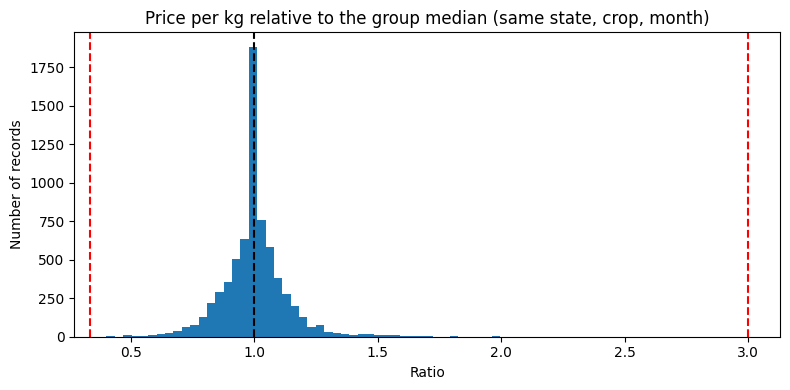

In [5]:
# Plotting the distribution of ratios
scope['ratio'].plot(kind='hist', bins=50, figsize=(8, 4))
plt.axvline(1, color='black', linestyle='--')       # a typical record
plt.axvline(3, color='red', linestyle='--')         # upper threshold
plt.axvline(1/3, color='red', linestyle='--')       # lower threshold
plt.title('Price per kg relative to the group median (same state, crop, month)')
plt.xlabel('Ratio')
plt.ylabel('Number of records')
plt.tight_layout()
plt.show()

### 4. Building the monthly table
Forecasting needs one price per state, crop and month: the median across markets, with the number of markets behind it.

In [6]:
# Calculating the monthly median price per kg and the number of markets
monthly = (scope.groupby(['admin1', 'commodity', 'month'])
           .agg(price=('price_per_kg', 'median'), n_markets=('market_id', 'nunique'))
           .reset_index())

print(monthly.shape)
print(monthly['n_markets'].describe())

(705, 5)
count    705.000000
mean       9.836879
std        3.992223
min        1.000000
25%        8.000000
50%       10.000000
75%       11.000000
max       22.000000
Name: n_markets, dtype: float64


In [7]:
# Building the full grid: every state, commodity and month from Jan 2016 to Oct 2026
months = pd.period_range('2016-01', '2026-10', freq='M')
grid = pd.MultiIndex.from_product([states, commodities, months],
                                  names=['admin1', 'commodity', 'month']).to_frame(index=False)

# Attaching the monthly prices to the grid
full = grid.merge(monthly, on=['admin1', 'commodity', 'month'], how='left')
full['n_markets'] = full['n_markets'].fillna(0).astype(int)

print(full.shape)
print('Months with no data:', full['price'].isnull().sum())
print(full[full['price'].isnull()].groupby(['commodity', 'admin1']).size())

(780, 5)
Months with no data: 75
commodity     admin1
Groundnuts    Borno     13
              Yobe      24
Millet        Borno      7
              Yobe      13
Rice (local)  Borno      5
              Yobe      13
dtype: int64


### 5. Months with too few markets
A price from 1-2 markets can be a single market's price, so months under 3 markets are treated as missing.

In [8]:
# Counting months with only 1-2 markets, by year
low = full[(full['n_markets'] > 0) & (full['n_markets'] < 3)]
print('Months with 1-2 markets:', len(low))
print(low.groupby(low['month'].dt.year).size())

# Treating months with fewer than 3 markets as missing
full.loc[full['n_markets'] < 3, 'price'] = np.nan
print('Months missing after the 3-market rule:', full['price'].isnull().sum())

Months with 1-2 markets: 45
month
2016     4
2020     4
2021     2
2022    28
2023     4
2024     3
dtype: int64
Months missing after the 3-market rule: 120


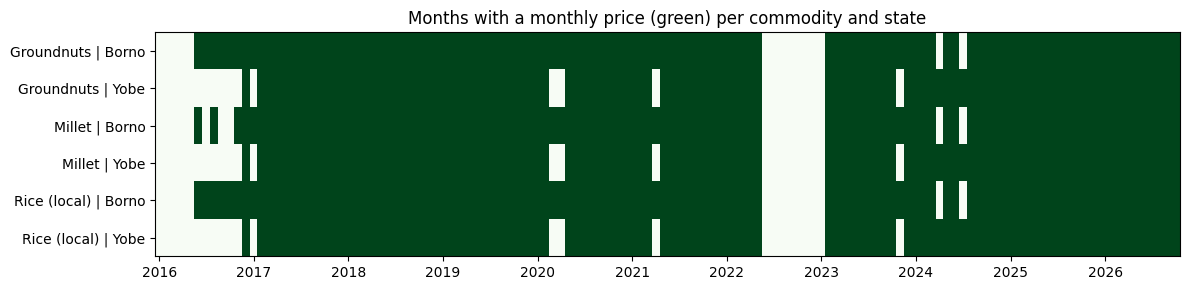

In [9]:
# Building a table of months with a price (1) or without (0)
present = full.assign(has_price=full['price'].notna().astype(int)).pivot_table(
    index=['commodity', 'admin1'], columns='month', values='has_price')

# Plotting the gap map (green = price available)
fig, ax = plt.subplots(figsize=(12, 3))
ax.imshow(present.values, aspect='auto', cmap='Greens', interpolation='nearest')
ax.set_yticks(range(len(present)))
ax.set_yticklabels([f'{c} | {s}' for c, s in present.index])
year_pos = [i for i, m in enumerate(present.columns) if m.month == 1]
ax.set_xticks(year_pos)
ax.set_xticklabels([str(present.columns[i].year) for i in year_pos])
ax.set_title('Months with a monthly price (green) per commodity and state')
plt.tight_layout()
plt.show()

### 6. Filling short gaps
Gaps of 1-2 months are bridged on log prices and flagged. Longer gaps stay missing: filling them would mean inventing data.

In [10]:
# Sorting so each series runs in date order
full = full.sort_values(['commodity', 'admin1', 'month']).reset_index(drop=True)

# Filling gaps of 2 months or fewer, one series at a time
parts = []
for (c, s), g in full.groupby(['commodity', 'admin1']):
    g = g.copy()
    log_p = np.log(g['price'])
    filled = log_p.interpolate(limit_area='inside')
    # Measuring the length of each run of missing months
    is_gap = log_p.isnull()
    run_id = (is_gap != is_gap.shift()).cumsum()
    run_len = is_gap.groupby(run_id).transform('sum')
    # Keeping the fill only where the whole gap is 2 months or shorter
    filled[is_gap & (run_len > 2)] = np.nan
    g['is_interpolated'] = is_gap & filled.notnull()
    g['price_per_kg_ngn'] = np.exp(filled)
    parts.append(g)
clean = pd.concat(parts)

print('Interpolated months:', int(clean['is_interpolated'].sum()))
print('Still missing:', int(clean['price_per_kg_ngn'].isnull().sum()))

Interpolated months: 24
Still missing: 96


In [11]:
# Finding the first month with a price for each commodity and state
first_price = (clean.dropna(subset=['price_per_kg_ngn'])
               .groupby(['commodity', 'admin1'])['month'].min())
print(first_price)

commodity     admin1
Groundnuts    Borno     2016-06
              Yobe      2016-12
Millet        Borno     2016-06
              Yobe      2016-12
Rice (local)  Borno     2016-06
              Yobe      2016-12
Name: month, dtype: period[M]


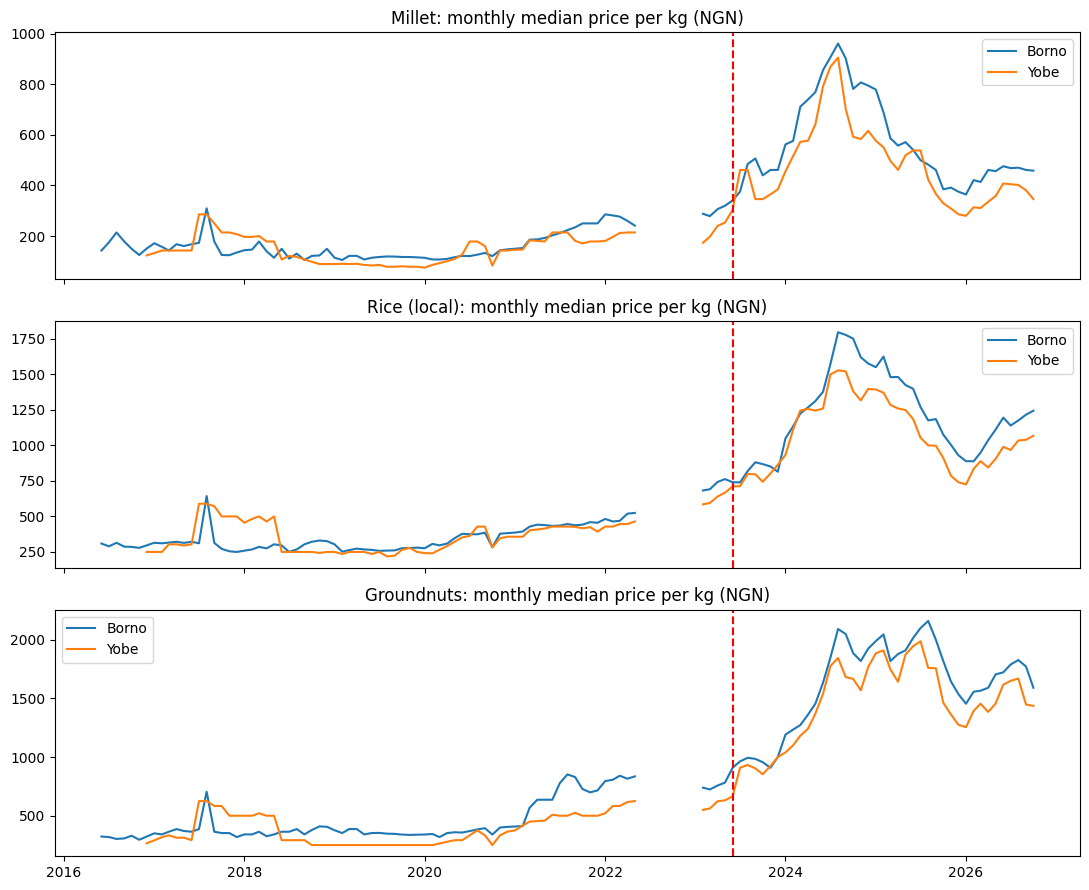

In [12]:
# Converting month to a plain date for plotting
clean['date'] = clean['month'].dt.to_timestamp()

# Plotting monthly median price per kg, one chart per crop
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, crop in zip(axes, commodities):
    for state in states:
        d = clean[(clean['commodity'] == crop) & (clean['admin1'] == state)]
        ax.plot(d['date'], d['price_per_kg_ngn'], label=state)
    ax.axvline(pd.Timestamp('2023-06-01'), color='red', linestyle='--')  # mid-2023
    ax.set_title(crop + ': monthly median price per kg (NGN)')
    ax.legend()
plt.tight_layout()
plt.show()

### 7. Saving the clean dataset

In [13]:
# Selecting and renaming the final columns
out = clean[['date', 'admin1', 'commodity', 'price_per_kg_ngn', 'n_markets', 'is_interpolated']]
out = out.rename(columns={'admin1': 'state'})

# Saving for Notebook 3
out.to_csv('clean_monthly_prices.csv', index=False)
print(out.shape)
out.head()

(780, 6)


,date,state,commodity,price_per_kg_ngn,n_markets,is_interpolated
0,2016-01-01,Borno,Groundnuts,NaN,1,False
1,2016-02-01,Borno,Groundnuts,NaN,0,False
2,2016-03-01,Borno,Groundnuts,NaN,0,False
3,2016-04-01,Borno,Groundnuts,NaN,0,False
4,2016-05-01,Borno,Groundnuts,NaN,0,False


## Data preparation conclusions

### Decisions and why
- Retail prices from January 2016, Borno and Yobe, millet, rice (local) and groundnuts: the scope from the audit (6,935 records).
- NGN per kg: baskets differ (groundnuts 2.2 KG, millet 2.6 KG, rice 2.7 KG), so prices are divided by basket weight to be comparable.
- No records removed: none was more than 3x above or below the median for its state, crop and month (ratios ranged from 0.40 to 2.10).
- Median across markets: one unusual market cannot pull the monthly value. A typical month has 10 reporting markets (range 1 to 22).
- Minimum 3 markets per month: a price from 1-2 markets can be a single market's price, so those months are treated as missing (3 is a judgement call).
- Gaps of 1-2 months interpolated (24 months, flagged); longer gaps left missing (96), because filling them would mean inventing data.

### Limitations
- 28 of the 45 months with only 1-2 markets fall in 2022, just before the mid-2023 price shock.
- Series start after January 2016: Borno in June 2016 and Yobe in December 2016.

### Output
clean_monthly_prices.csv: 780 rows (2 states x 3 crops x 130 months), January 2016 to October 2026.